# Лабораторная работа № 2.1
---
«Построение модели линейной регрессии»

Рязанцев Георгий Борисович

In [1]:
from pandas import read_csv
data = read_csv('Analysis.csv', sep=';')
data.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2,Y3
0,106.5,20.33,55.9,4.92,1.354,65.192,157,0.052,448.528,13.4,36.038
1,126.8,30.04,74.0,2.90,0.271,57.439,154,0.099,-167.993,-26.2,26.500
2,35.8,38.94,87.4,0.87,1.770,60.307,138,0.054,11.154,0.8,21.485
3,89.6,28.43,75.5,3.21,2.122,38.227,145,0.021,109.001,7.7,27.800
4,19.4,31.70,72.2,0.26,2.251,61.748,137,0.032,-36.044,-3.0,18.746


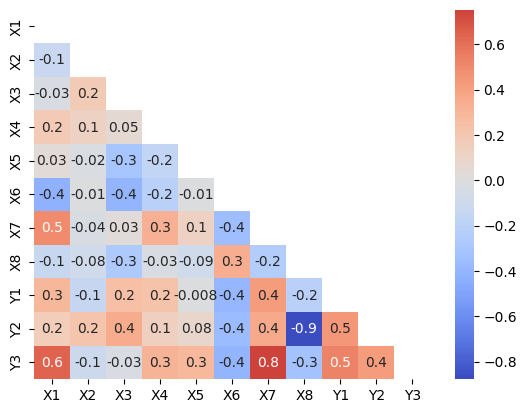

In [2]:
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt

def heatmap(data=data):
    matrix = np.triu(data.corr())
    sns.heatmap(data.corr(), annot=True, mask=matrix, cmap='coolwarm', center=0, fmt = ".1g")
    plt.show()

heatmap()

In [3]:
corr = data.corr()

for col in corr.columns:
    if not col.startswith('Y'):
        continue

    related = corr.loc[col, abs(corr[col]) >= 0.28].index.tolist()
    related = [x for x in related if not x.startswith('Y') and x != col]

    if related:
        print(col, "—", ", ".join(related))
    else:
        print(col, "— none")

Y1 — X1, X6, X7
Y2 — X3, X6, X7, X8
Y3 — X1, X4, X5, X6, X7, X8


### почему список пар отличается от методички

В методичке пары отбирались по правилу $|r| \ge 0{,}3$ на тепловой карте (рис. 2.3), где числа округлены до одной значащей цифры (`fmt='.1g'`): значение 0,291 там отображается как «0,3». В ячейке выше использован порог 0,28 по **точным** значениям, поэтому в список попадают ещё и «пограничные» пары.

Для $Y_1$ в методичке выделен только $X_6$, а в этих данных ещё и $X_7$ ($r = 0{,}43$). Причина в самих данных: рис. 2.3 построен по набору с выбросом $Y_1 \approx 16000$ (рис. 2.5), одна такая точка почти обнуляет корреляции $Y_1$ с большинством факторов (на рис. 2.3 для $X_1$ и $X_7$ стоят 0,03 и 0,04, а в файле без выброса — 0,30 и 0,43). Файл `Analysis.csv` этого выброса уже не содержит (максимум $Y_1 = 629$, как на рис. 2.6). Корреляции $Y_2$ и $Y_3$ с методичкой совпадают.

Ячейка ниже проверяет это: порог 0,3 по точным значениям и контроль выброса.

In [4]:
corr = data.corr()
x_cols = [f'X{i}' for i in range(1, 9)]

for y_col in ['Y1', 'Y2', 'Y3']:
    r = corr.loc[y_col, x_cols]
    strong = r[r.abs() >= 0.3]
    border = r[(r.abs() >= 0.28) & (r.abs() < 0.3)]
    print(f"{y_col}: |r| >= 0.3 -> " + ", ".join(f"{k} ({v:+.3f})" for k, v in strong.items()))
    if len(border):
        print("     пограничные (0.28 <= |r| < 0.3) -> " + ", ".join(f"{k} ({v:+.3f})" for k, v in border.items()))

print()
print("Y1: максимум =", data['Y1'].max(), "| наблюдений с Y1 > 1000:", int((data['Y1'] > 1000).sum()))

Y1: |r| >= 0.3 -> X6 (-0.391), X7 (+0.426)
     пограничные (0.28 <= |r| < 0.3) -> X1 (+0.296)
Y2: |r| >= 0.3 -> X3 (+0.352), X6 (-0.366), X7 (+0.364), X8 (-0.878)
Y3: |r| >= 0.3 -> X1 (+0.647), X4 (+0.318), X6 (-0.410), X7 (+0.752), X8 (-0.327)
     пограничные (0.28 <= |r| < 0.3) -> X5 (+0.291)

Y1: максимум = 629.236 | наблюдений с Y1 > 1000: 0


In [5]:
def redefine(data=data, ax='X7', ay='Y1'):
    global x
    global y
    x = data[ax]
    y = data[ay]

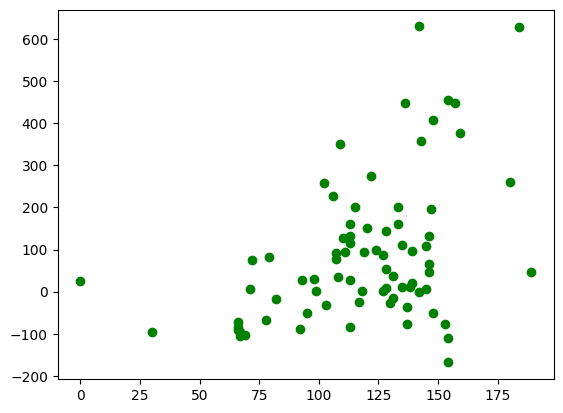

In [6]:
redefine()
plt.plot(x,y,'o',color='green')
plt.show()

In [7]:
#-----#
cols = ['X7', 'Y1']

Q1 = data[cols].quantile(0.25)
Q3 = data[cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = ((data[cols] < lower_bound) | (data[cols] > upper_bound)).any(axis=1)

data_clean = data[~outlier_mask]

data_clean = data_clean[cols]

data_clean.head()

,X7,Y1
1,154,-167.993
2,138,11.154
3,145,109.001
4,137,-36.044
5,148,-49.645


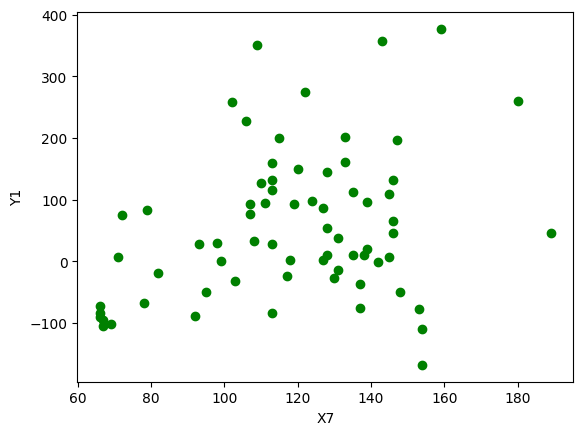

In [8]:
redefine(data_clean)
plt.plot(x,y,'o',color='green')
plt.xlabel('X7')
plt.ylabel('Y1')
plt.show()

### какие данные идут в модель

Ячейка с IQR-фильтром выше убирает строки с «выбросами» по $X_7$ и $Y_1$ (ниже видно, сколько). **Методичка этого шага не выполняет**: единственный выброс (≈16000) в файле уже удалён, а модели на рис. 2.8, 2.10 и 2.12 построены на всех 77 наблюдениях (`No. Observations: 77`). Поэтому основные модели ниже строятся на полном `data`, а проверка устойчивости к выбросам выполнена ниже для основной пары методички $X_6$–$Y_1$ (ячейка после рис. 2.8). Ваш `data_clean` по $X_7$ и $Y_1$ (69 строк) нужен для диаграммы выше и в модели не используется.

In [9]:
print("Всего наблюдений:", len(data), "| после IQR-фильтра по X7 и Y1:", len(data_clean), "| удалено:", len(data) - len(data_clean))

Всего наблюдений: 77 | после IQR-фильтра по X7 и Y1: 69 | удалено: 8


$R^2 = 0{,}181$, $b_{X_7} = 2{,}16$ ($p < 0{,}001$): при росте $X_7$ на единицу $Y_1$ в среднем растёт на 2,16 единицы. Это дополнительная модель: в методичке $Y_1$ связывается с $X_6$ (следующий раздел). На очищенных от выброса данных $X_7$ даже сильнее связан с $Y_1$, чем $X_6$ ($r = 0{,}43$ против $-0{,}39$), поэтому обе модели оставлены.

## Модели по методичке

Общие функции: построение OLS и сверка результатов со значениями на рисунках методички (допуск: относительная погрешность 0,2 %, потому что в методичке значения округлены).

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt

def fit_ols(df, y_col, x_cols):
    """OLS с константой: y = b0 + b1*x1 + ..."""
    return sm.OLS(df[y_col], sm.add_constant(df[x_cols])).fit()

def compare_with_book(model, book_params, book_stats):
    """Таблица: значение в моем расчёте / в методичке / совпадение."""
    rows = [(name, model.params[name], val) for name, val in book_params.items()]
    actual = {'R-squared': model.rsquared, 'Adj. R-squared': model.rsquared_adj,
              'F-statistic': model.fvalue, 'Prob (F-statistic)': model.f_pvalue,
              'AIC': model.aic, 'BIC': model.bic}
    rows += [(name, actual[name], val) for name, val in book_stats.items()]
    out = pd.DataFrame(rows, columns=['показатель', 'реальное', 'в методичке'])
    out['совпадает'] = [bool(np.isclose(a, b, rtol=2e-3, atol=2e-4)) for _, a, b in rows]
    return out

### Y1 ~ X6 (рис. 2.4–2.8)

В методичке $Y_1$ объясняется переменной $X_6$ (единственная пара с $|r| \ge 0{,}3$ на рис. 2.3).

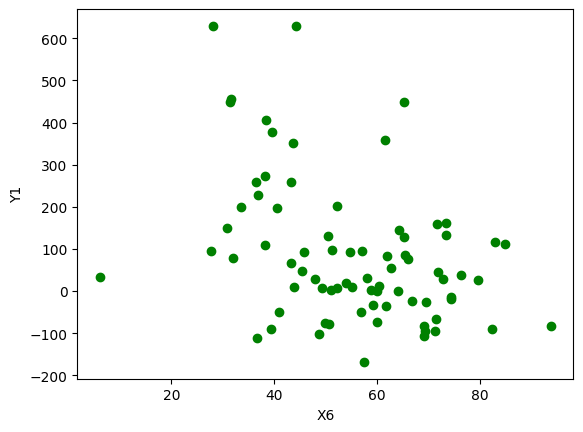

                            OLS Regression Results                            
Dep. Variable:                     Y1   R-squared:                       0.153
Model:                            OLS   Adj. R-squared:                  0.141
Method:                 Least Squares   F-statistic:                     13.50
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           0.000445
Time:                        02:50:53   Log-Likelihood:                -497.23
No. Observations:                  77   AIC:                             998.5
Df Residuals:                      75   BIC:                             1003.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        311.6666     63.465      4.911      0.0

In [12]:
plt.plot(data['X6'], data['Y1'], 'o', color='green')
plt.xlabel('X6')
plt.ylabel('Y1')
plt.show()

model_y1 = fit_ols(data, 'Y1', ['X6'])
print(model_y1.summary())

In [13]:
compare_with_book(
    model_y1,
    book_params={'const': 311.6666, 'X6': -4.0608},
    book_stats={'R-squared': 0.153, 'Adj. R-squared': 0.141, 'F-statistic': 13.50,
                'Prob (F-statistic)': 0.000445, 'AIC': 998.5, 'BIC': 1003.0},
)

,показатель,реальное,в методичке,совпадает
0,const,311.666646,311.666600,True
1,X6,-4.060775,-4.060800,True
2,R-squared,0.152559,0.153000,True
3,Adj. R-squared,0.141259,0.141000,True
4,F-statistic,13.501687,13.500000,True
5,Prob (F-statistic),0.000445,0.000445,True
6,AIC,998.452185,998.500000,True
7,BIC,1003.139796,1003.000000,True


**Интерпретация.**
- $Y_1 = 311{,}67 - 4{,}06\,X_6$. Знак «минус» подтверждает обратную зависимость.
- $b_{X_6} = -4{,}06$ означает: при росте $X_6$ на **1 единицу** $Y_1$ в среднем падает на 4,06 **единицы $Y_1$**. В методичке написано «при увеличении $X_6$ на 1 % величина $Y_1$ сократится на 4,1 %». Это неточная формулировка: коэффициент регрессии измеряется в единицах $Y_1$ на единицу $X_6$, а не в процентах.
- $R^2 = 0{,}153$: модель объясняет около 15 % вариации $Y_1$. Теснота связи средняя ($|r| = 0{,}39$), но заметная часть вариации остаётся необъяснённой.
- Оба коэффициента значимы ($p < 0{,}001$), модель в целом значима ($p_F = 0{,}000445$).

**Проверка устойчивости (чистка выбросов по IQR).** Если дополнительно убрать строки-выбросы по $X_6$ и $Y_1$, модель остаётся значимой, но слабеет. Это ожидаемо: числа не должны совпасть с методичкой, она эту чистку не делает.

In [14]:
cols = ['X6', 'Y1']
q1, q3 = data[cols].quantile(0.25), data[cols].quantile(0.75)
iqr = q3 - q1
mask = ((data[cols] < q1 - 1.5 * iqr) | (data[cols] > q3 + 1.5 * iqr)).any(axis=1)
data_x6_clean = data[~mask]

model_y1_clean = fit_ols(data_x6_clean, 'Y1', ['X6'])
print(f"Удалено строк: {mask.sum()}, осталось: {len(data_x6_clean)}")
print(f"Без чистки : b(X6) = {model_y1.params['X6']:.3f}, R2 = {model_y1.rsquared:.3f}, p = {model_y1.pvalues['X6']:.4f}")
print(f"После чистки: b(X6) = {model_y1_clean.params['X6']:.3f}, R2 = {model_y1_clean.rsquared:.3f}, p = {model_y1_clean.pvalues['X6']:.4f}")

Удалено строк: 7, осталось: 70
Без чистки : b(X6) = -4.061, R2 = 0.153, p = 0.0004
После чистки: b(X6) = -2.640, R2 = 0.105, p = 0.0061


После чистки $b_{X_6} \approx -2{,}64$ ($p = 0{,}006$), $R^2 \approx 0{,}105$: из 7 удалённых строк 6 имеют очень большие $Y_1$ (407–629), и 5 из них при $X_6$ ниже среднего (28–44); именно они задавали крутой отрицательный наклон. Направление связи сохраняется, значимость тоже; численно отличие от методички объясняется тем, что методичка выбросы не убирает.

### Y2 ~ X3, X6, X7, X8 (рис. 2.9–2.10)

Сначала модель на всех четырёх связанных с $Y_2$ факторах.

In [15]:
model_y2_full = fit_ols(data, 'Y2', ['X3', 'X6', 'X7', 'X8'])
print(model_y2_full.summary())
print()
print("p-value X6 =", round(model_y2_full.pvalues['X6'], 3))

                            OLS Regression Results                            
Dep. Variable:                     Y2   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     77.19
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.76e-25
Time:                        02:50:53   Log-Likelihood:                -302.65
No. Observations:                  77   AIC:                             615.3
Df Residuals:                      72   BIC:                             627.0
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -21.5008     12.386     -1.736      0.0

$p_{X_6} = 0{,}664$ (в методичке «66,4 %»), это намного выше 0,05, значит $X_6$ статистически незначим и исключается. Остальные факторы значимы, их оставляем.

In [16]:
model_y2 = fit_ols(data, 'Y2', ['X3', 'X7', 'X8'])
print(model_y2.summary())
compare_with_book(
    model_y2,
    book_params={'const': -17.3159, 'X3': 0.1523, 'X7': 0.1411, 'X8': -266.3003},
    book_stats={'R-squared': 0.810, 'Adj. R-squared': 0.803, 'F-statistic': 104.0,
                'Prob (F-statistic)': 2.72e-26, 'AIC': 613.5, 'BIC': 622.9},
)

                            OLS Regression Results                            
Dep. Variable:                     Y2   R-squared:                       0.810
Model:                            OLS   Adj. R-squared:                  0.803
Method:                 Least Squares   F-statistic:                     104.0
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.72e-26
Time:                        02:50:53   Log-Likelihood:                -302.75
No. Observations:                  77   AIC:                             613.5
Df Residuals:                      73   BIC:                             622.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -17.3159      7.793     -2.222      0.0

,показатель,реальное,в методичке,совпадает
0,const,-1.731590e+01,-1.731590e+01,True
1,X3,1.522715e-01,1.523000e-01,True
2,X7,1.410735e-01,1.411000e-01,True
3,X8,-2.663003e+02,-2.663003e+02,True
4,R-squared,8.104000e-01,8.100000e-01,True
5,Adj. R-squared,8.026082e-01,8.030000e-01,True
6,F-statistic,1.040070e+02,1.040000e+02,True
7,Prob (F-statistic),2.721599e-26,2.720000e-26,True
8,AIC,6.135032e+02,6.135000e+02,True
9,BIC,6.228784e+02,6.229000e+02,True


**Результаты совпадают с рис. 2.10.**

**Интерпретация.** $Y_2 = -17{,}32 + 0{,}152\,X_3 + 0{,}141\,X_7 - 266{,}3\,X_8$.
- $X_3$ и $X_7$ влияют положительно, $X_8$ отрицательно.
- Коэффициент при $X_8$ выглядит огромным только из-за масштаба: $X_8$ обычно лежит в пределах 0,005–0,1, поэтому рост $X_8$ на 0,01 снижает $Y_2$ на ≈2,7.
- $R^2 = 0{,}81$, все коэффициенты значимы на уровне 5 %.

#### Важная оговорка: модель Y2 держится на одном наблюдении

Цифры методички воспроизведены, но диагностика показывает, что высокий $R^2$ почти целиком определяется **одной строкой** (индекс 76: $X_8 = 0{,}766$ при медиане 0,036 и $Y_2 = -212{,}6$ при медиане 3,0). Ниже это проверено через расстояние Кука и повторной оценкой без этой строки.

In [17]:
X = sm.add_constant(data[['X3', 'X7', 'X8']]).to_numpy(dtype=float)
y = data['Y2'].to_numpy(dtype=float)
hat = np.diag(X @ np.linalg.inv(X.T @ X) @ X.T)          # рычаг (leverage)
resid = y - X @ np.linalg.solve(X.T @ X, X.T @ y)
k = X.shape[1]
s2 = resid @ resid / (len(y) - k)
cooks = resid**2 / (k * s2) * hat / (1 - hat)**2          # расстояние Кука

i = int(np.argmax(cooks))
print(f"Самое влиятельное наблюдение: индекс {i}, X8 = {data.loc[i, 'X8']}, Y2 = {data.loc[i, 'Y2']}")
print(f"Расстояние Кука = {cooks[i]:.2f} (ориентир 4/n = {4/len(y):.3f}), рычаг = {hat[i]:.3f}")

model_y2_wo = fit_ols(data.drop(index=i), 'Y2', ['X3', 'X7', 'X8'])
print()
print("Без этого наблюдения:")
print(pd.DataFrame({'коэффициент': model_y2_wo.params, 'p-value': model_y2_wo.pvalues}).round(4))
print(f"R2: {model_y2.rsquared:.3f} (все 77)  ->  {model_y2_wo.rsquared:.3f} (76 наблюдений)")

Самое влиятельное наблюдение: индекс 76, X8 = 0.766, Y2 = -212.6
Расстояние Кука = 4.89 (ориентир 4/n = 0.052), рычаг = 0.933

Без этого наблюдения:
       коэффициент  p-value
const     -21.5406   0.0139
X3          0.1517   0.0147
X7          0.1524   0.0014
X8       -191.0595   0.0049
R2: 0.810 (все 77)  ->  0.315 (76 наблюдений)


Без строки 76: $R^2$ падает с 0,81 до ≈0,32, коэффициент при $X_8$ с −266 до ≈−191, но остаётся значимым ($p \approx 0{,}005$); коэффициент при $X_3$ не меняется (0,152), при $X_7$ меняется слабо (0,141 → 0,152). **направление влияния факторов ($X_3 +$, $X_7 +$, $X_8 -$) устойчиво, а сила связи в методичке завышена одной аномальной точкой.**

In [19]:
model_y3 = fit_ols(data, 'Y3', ['X1', 'X4', 'X5', 'X7', 'X8'])
print(model_y3.summary())
compare_with_book(
    model_y3,
    book_params={'const': -0.7171, 'X1': 0.0739, 'X4': 1.1623, 'X5': 0.0276, 'X7': 0.1354, 'X8': -15.8981},
    book_stats={'R-squared': 0.744, 'Adj. R-squared': 0.726, 'F-statistic': 41.22,
                'Prob (F-statistic)': 1.11e-19, 'AIC': 474.7, 'BIC': 488.8},
)

                            OLS Regression Results                            
Dep. Variable:                     Y3   R-squared:                       0.744
Model:                            OLS   Adj. R-squared:                  0.726
Method:                 Least Squares   F-statistic:                     41.22
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           1.11e-19
Time:                        02:50:53   Log-Likelihood:                -231.36
No. Observations:                  77   AIC:                             474.7
Df Residuals:                      71   BIC:                             488.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.7171      2.379     -0.301      0.7

,показатель,реальное,в методичке,совпадает
0,const,-7.171347e-01,-7.171000e-01,True
1,X1,7.389126e-02,7.390000e-02,True
2,X4,1.162280e+00,1.162300e+00,True
3,X5,2.764089e-02,2.760000e-02,True
4,X7,1.354415e-01,1.354000e-01,True
5,X8,-1.589812e+01,-1.589810e+01,True
6,R-squared,7.437547e-01,7.440000e-01,True
7,Adj. R-squared,7.257092e-01,7.260000e-01,True
8,F-statistic,4.121564e+01,4.122000e+01,True
9,Prob (F-statistic),1.108639e-19,1.110000e-19,True


**Результаты совпадают с рис. 2.12.**

**Интерпретация.** Прямое влияние на $Y_3$ оказывают $X_1$ (+0,074), $X_4$ (+1,16), $X_5$ (+0,028), $X_7$ (+0,135); $X_8$ влияет отрицательно (−15,9). Все коэффициенты значимы на 5 % (самый слабый: $X_4$, $p = 0{,}044$); свободный член незначим ($p = 0{,}76$), это нормально. $R^2 = 0{,}744$, модель в целом значима.

## Самостоятельная работа

### 1. Шаговая регрессия

Реализован двунаправленный пошаговый отбор по p-value (в `statsmodels` готовой функции нет): фактор добавляется, если его $p < 0{,}05$, и удаляется, если после добавления других его $p > 0{,}10$. Отбор идёт из всех факторов $X_1 \ldots X_8$ без предварительной корреляционной фильтрации.

In [20]:
X_all = data[[f'X{i}' for i in range(1, 9)]]

def stepwise_select(X, y, p_in=0.05, p_out=0.10):
    """Двунаправленный пошаговый отбор признаков по p-value (OLS)."""
    included = []
    while True:
        changed = False
        excluded = [c for c in X.columns if c not in included]
        if excluded:                                   # шаг вперёд
            pv = {c: fit_ols(pd.concat([X[included + [c]], y], axis=1), y.name, included + [c]).pvalues[c]
                  for c in excluded}
            best = min(pv, key=pv.get)
            if pv[best] < p_in:
                included.append(best)
                changed = True
        if included:                                   # шаг назад
            m = fit_ols(pd.concat([X[included], y], axis=1), y.name, included)
            p = m.pvalues.drop('const')
            if p.max() > p_out:
                included.remove(p.idxmax())
                changed = True
        if not changed:
            return included

step_models = {}
for y_col in ['Y1', 'Y2', 'Y3']:
    cols = stepwise_select(X_all, data[y_col])
    step_models[y_col] = fit_ols(data, y_col, cols)
    m = step_models[y_col]
    print(f"{y_col}: отобраны {cols}, R2 = {m.rsquared:.3f}, Adj.R2 = {m.rsquared_adj:.3f}")
    print("   p-value:", {k: round(v, 4) for k, v in m.pvalues.items()})

Y1: отобраны ['X7', 'X6'], R2 = 0.247, Adj.R2 = 0.227
   p-value: {'const': 0.6522, 'X7': 0.0032, 'X6': 0.0129}
Y2: отобраны ['X8', 'X7', 'X2', 'X3'], R2 = 0.830, Adj.R2 = 0.820
   p-value: {'const': 0.0007, 'X8': 0.0, 'X7': 0.001, 'X2': 0.0053, 'X3': 0.0362}
Y3: отобраны ['X7', 'X1', 'X5', 'X8', 'X4'], R2 = 0.744, Adj.R2 = 0.726
   p-value: {'const': 0.7639, 'X7': 0.0, 'X1': 0.0, 'X5': 0.0004, 'X8': 0.0267, 'X4': 0.0443}


**Выводы.**
- $Y_1$: отобраны $X_7$ и $X_6$ ($R^2 = 0{,}247$), то есть оба фактора, выделенные корреляциями, в паре работают лучше, чем каждый по отдельности ($0{,}181$ и $0{,}153$).
- $Y_2$: отобраны $X_8, X_7, X_2, X_3$ ($R^2 = 0{,}830$). $X_2$ (парная $r = 0{,}22$) не проходила порог 0,3 в методичке, но значима ($p = 0{,}005$) в присутствии остальных факторов, то есть отбор по парным корреляциям её теряет. Оговорка про строку 76 выше относится и к этой модели: по отдельной проверке без этой строки отбор выбирает тот же набор ($X_7, X_8, X_2, X_3$), но $R^2$ падает с 0,83 до 0,38.
- $Y_3$: отобраны ровно $X_7, X_1, X_5, X_8, X_4$ — **тот же набор, что в методичке**, что подтверждает выбор модели рис. 2.12.
- Оговорка: p-value после отбора по p-value оптимистичны, поэтому в п. 3 модели сравниваются на кросс-валидации.

### 2. Ridge- и Lasso-регрессия

Факторы стандартизируются (иначе штраф несправедлив к переменным с разным масштабом, например $X_8 \sim 0{,}04$ и $X_5 \sim 23$), параметр регуляризации $\alpha$ подбирается кросс-валидацией. Коэффициенты ниже — для стандартизированных факторов, то есть сравнимы между собой.

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV

ALPHAS = np.logspace(-4, 3, 60)

def ridge_model():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS))

def lasso_model():
    return make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=100000))

for y_col in ['Y1', 'Y2', 'Y3']:
    ridge = ridge_model().fit(X_all, data[y_col])
    lasso = lasso_model().fit(X_all, data[y_col])
    table = pd.DataFrame({'Ridge': ridge[-1].coef_, 'Lasso': lasso[-1].coef_}, index=X_all.columns).round(3)
    print(f"{y_col}: alpha Ridge = {ridge[-1].alpha_:.4g}, alpha Lasso = {lasso[-1].alpha_:.4g}")
    print(table.T.to_string())
    print()

Y1: alpha Ridge = 65.1, alpha Lasso = 18.94
           X1      X2      X3      X4     X5      X6      X7    X8
Ridge  12.192 -14.301  17.442  12.655  0.508 -20.683  27.506 -8.23
Lasso   0.000  -5.010  10.928   0.000 -0.000 -27.257  42.269 -0.00

Y2: alpha Ridge = 0.0001, alpha Lasso = 0.02488
          X1     X2     X3     X4     X5     X6     X7      X8
Ridge -0.138  3.718  3.779  1.565  1.348  0.760  4.519 -22.566
Lasso -0.114  3.708  3.727  1.532  1.307  0.698  4.482 -22.545

Y3: alpha Ridge = 16.61, alpha Lasso = 0.1927
          X1     X2     X3     X4     X5    X6     X7     X8
Ridge  2.956 -0.552 -0.189  1.242  1.864 -0.58  3.811 -1.262
Lasso  3.346 -0.415  0.000  1.148  2.037 -0.07  4.446 -1.232



**Выводы.**
- $Y_1$: Lasso обнуляет $X_1, X_4, X_5, X_8$ и оставляет $X_7$ (+42,3), $X_6$ (−27,3), $X_3$, $X_2$, то есть тот же вывод, что и шаговая регрессия и корреляции: ключевые факторы $X_7$ и $X_6$. Ridge ничего не обнуляет, а сжимает все коэффициенты.
- $Y_2$: подобранный $\alpha$ минимален (у Ridge — на нижней границе сетки), штраф почти ничего не меняет, и обе модели практически совпадают с OLS. Это нормально: факторы слабо коррелируют между собой (максимум $|r| \approx 0{,}49$, у пары $X_1$–$X_7$), мультиколлинеарности, которую лечит регуляризация, здесь нет (предупреждение statsmodels о числе обусловленности объяснено в примечании выше).
- $Y_3$: Lasso почти обнуляет $X_6$ (−0,07) и $X_3$ (0), согласуясь с тем, что $X_6$ незначим в OLS.

### 3. Качество моделей: MSE и RMSE

$$MSE = \frac{1}{n}\sum (y_i - \hat y_i)^2, \qquad RMSE = \sqrt{MSE}.$$

Сначала пример из методички как проверка функции (ожидается $RMSE \approx 0{,}697$).

In [22]:
import math
y_actual = [1, 2, 3, 4, 5]
y_predicted = [1.6, 2.5, 2.9, 3, 4.1]

MSE = np.square(np.subtract(y_actual, y_predicted)).mean()
RMSE = math.sqrt(MSE)
print("MSE =", round(MSE, 4), "| RMSE =", round(RMSE, 4))

MSE = 0.486 | RMSE = 0.6971


Сравниваются пять моделей для каждой из трёх переменных: OLS с факторами из методички, OLS на всех $X_1 \ldots X_8$, шаговая регрессия, Ridge, Lasso. Метрики считаются тремя способами:
- **train** — на обучающих 80 %;
- **test** — на отложенных 20 % (`random_state=42`);
- **CV** — 5-кратная кросс-валидация на всех 77 наблюдениях (в каждом фолде заново подбираются признаки и $\alpha$, чтобы не было утечки).

Принцип из методички: «модель должна работать для незнакомых данных», поэтому судить надо по test и CV, а не по train. Если test и CV дают разный порядок моделей, это объяснено в блоке «Почему test и CV дают разные лучшие модели» после таблицы. Метод OLS здесь реализован через `LinearRegression`: точечные оценки те же, что у `sm.OLS`.

In [23]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error

class StepwiseOLS(BaseEstimator, RegressorMixin):
    """Шаговый отбор + OLS; отбор выполняется внутри fit(), поэтому честно работает в кросс-валидации."""
    def __init__(self, p_in=0.05, p_out=0.10):
        self.p_in = p_in
        self.p_out = p_out
    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(np.asarray(y), name='target')
        self.cols_ = stepwise_select(X, y, self.p_in, self.p_out) or [X.columns[0]]
        self.lr_ = LinearRegression().fit(X[self.cols_], y)
        return self
    def predict(self, X):
        return self.lr_.predict(pd.DataFrame(X)[self.cols_])

BOOK_SETS = {'Y1': ['X6'], 'Y2': ['X3', 'X7', 'X8'], 'Y3': ['X1', 'X4', 'X5', 'X7', 'X8']}

def make_models(y_col):
    return {
        'OLS (по методичке)': make_pipeline(ColumnTransformer([('sel', 'passthrough', BOOK_SETS[y_col])]), LinearRegression()),
        'OLS (все X1-X8)': LinearRegression(),
        'Stepwise': StepwiseOLS(),
        'Ridge': ridge_model(),
        'Lasso': lasso_model(),
    }

rows = []
for y_col in ['Y1', 'Y2', 'Y3']:
    X_tr, X_te, y_tr, y_te = train_test_split(X_all, data[y_col], test_size=0.2, random_state=42)
    for name, model in make_models(y_col).items():
        model.fit(X_tr, y_tr)
        mse_tr = mean_squared_error(y_tr, model.predict(X_tr))
        mse_te = mean_squared_error(y_te, model.predict(X_te))
        mse_cv = -cross_val_score(model, X_all, data[y_col], scoring='neg_mean_squared_error',
                                  cv=KFold(5, shuffle=True, random_state=42)).mean()
        rows.append({'Y': y_col, 'модель': name,
                     'MSE train': mse_tr, 'RMSE train': np.sqrt(mse_tr),
                     'MSE test': mse_te, 'RMSE test': np.sqrt(mse_te),
                     'MSE CV': mse_cv, 'RMSE CV': np.sqrt(mse_cv),
                     'RMSE CV / std(Y)': np.sqrt(mse_cv) / data[y_col].std()})

metrics = pd.DataFrame(rows)
pd.set_option('display.width', 200)
metrics.round(2)

,Y,модель,MSE train,RMSE train,MSE test,RMSE test,MSE CV,RMSE CV,RMSE CV / std(Y)
0,Y1,OLS (по методичке),20014.22,141.47,40815.93,202.03,27342.43,165.36,0.98
1,Y1,OLS (все X1-X8),16519.03,128.53,38610.67,196.50,60075.65,245.10,1.45
2,Y1,Stepwise,18457.31,135.86,34458.47,185.63,66620.19,258.11,1.53
3,Y1,Ridge,17487.90,132.24,39121.19,197.79,34028.12,184.47,1.09
4,Y1,Lasso,17364.90,131.78,38829.56,197.05,44170.42,210.17,1.25
5,Y2,OLS (по методичке),152.24,12.34,164.74,12.84,196.07,14.00,0.49
6,Y2,OLS (все X1-X8),129.70,11.39,170.37,13.05,192.21,13.86,0.49
7,Y2,Stepwise,141.49,11.90,167.70,12.95,170.87,13.07,0.46
8,Y2,Ridge,129.70,11.39,170.37,13.05,292.43,17.10,0.60
9,Y2,Lasso,129.71,11.39,169.87,13.03,244.21,15.63,0.55


In [24]:
print("Среднее квадратичное отклонение самих Y (RMSE «прогноза средним»):")
print(data[['Y1', 'Y2', 'Y3']].std().round(2).to_string())
print()
print("RMSE по кросс-валидации (меньше = лучше):")
print(metrics.pivot(index='модель', columns='Y', values='RMSE CV').round(2).to_string())

Среднее квадратичное отклонение самих Y (RMSE «прогноза средним»):
Y1    168.65
Y2     28.53
Y3      9.71

RMSE по кросс-валидации (меньше = лучше):
Y                       Y1     Y2    Y3
модель                                 
Lasso               210.17  15.63  9.12
OLS (все X1-X8)     245.10  13.86  9.71
OLS (по методичке)  165.36  14.00  9.04
Ridge               184.47  17.10  8.50
Stepwise            258.11  13.07  9.29


Прежде чем делать выводы, проверим, чем объясняются большие ошибки при кросс-валидации: посчитаем вклад отдельных строк (модель по методичке для $Y_3$) и повторим сравнение для $Y_2$ без строки 76.

In [25]:
from sklearn.model_selection import cross_val_predict
cv5 = KFold(5, shuffle=True, random_state=42)

# Y3: вклад отдельных наблюдений в ошибку кросс-валидации
pred = cross_val_predict(make_models('Y3')['OLS (по методичке)'], X_all, data['Y3'], cv=cv5)
sq = pd.Series((data['Y3'] - pred) ** 2, index=data.index)
print(f"Y3: доля строки 76 в сумме квадратов ошибок CV = {sq[76] / sq.sum():.0%}; пять худших строк = {sq.nlargest(5).sum() / sq.sum():.0%}")
print("Строки, где Y3 = 0:", data.index[data['Y3'] == 0].tolist())
print()

# Y2: то же сравнение моделей без строки 76
d2 = data.drop(index=76)
X2 = d2[X_all.columns]
print(f"Y2 без строки 76 (std = {d2['Y2'].std():.2f}), RMSE по CV:")
for name, model in make_models('Y2').items():
    mse = -cross_val_score(model, X2, d2['Y2'], scoring='neg_mean_squared_error', cv=cv5).mean()
    print(f"  {name:20s} {np.sqrt(mse):6.2f}")

Y3: доля строки 76 в сумме квадратов ошибок CV = 65%; пять худших строк = 84%
Строки, где Y3 = 0: [23, 74, 75, 76]

Y2 без строки 76 (std = 14.97), RMSE по CV:
  OLS (по методичке)    13.26
  OLS (все X1-X8)       14.04
  Stepwise              13.05
  Ridge                 13.58
  Lasso                 14.47


**Как читать таблицу.**
- RMSE измеряется в единицах своей переменной и сравнивать его между $Y_1$, $Y_2$, $Y_3$ нельзя (их std: 169, 29 и 10). Поэтому добавлен столбец `RMSE CV / std(Y)`: значение 1 означает «не лучше прогноза средним», меньше 1 — лучше, больше 1 — хуже. Std считается по всей выборке; для $Y_2$ она завышена строкой 76 (28,5 против 14,97 без неё), поэтому значения 0,46–0,60 для $Y_2$ выглядят лучше, чем есть на деле.
- По **train** лучше всех модель с наибольшим числом факторов (OLS на всех $X$; в $Y_2$ с ней совпадает Ridge, у которого $\alpha$ почти нулевой): так и должно быть, это эффект подгонки под обучающие данные, а не качество.

**Почему test и CV дают разные «лучшие» модели.** Значения в обоих столбцах верны, но отвечают на разные вопросы. Test — один случайный разбиение (`random_state=42`), проверка на 16 строках. CV — 77 строк по очереди в роли проверочных. В отложенные 16 строк строка 76 не попала (осталась в обучении), а из строк с $Y_3 = 0$ попала только строка 74. Поэтому порядок моделей по test и по CV может не совпадать, и это не ошибка расчёта:
- $Y_1$: по test лучшая Stepwise (186), худшая OLS по методичке (202); по CV наоборот (165 против 258). На test все модели дают 186–202 при std отложенной выборки 210, то есть разница между ними всего ±5 %, и ни одна не предсказывает хорошо.
- $Y_2$: на test все модели 12,8–13,1 (разница менее 2 %) при std отложенной выборки 13,8. Разброс 13,1–17,1 в CV создаёт строка 76, попадающая в проверочный фолд.
- $Y_3$: на test RMSE 4,8–5,6 при std отложенной выборки 12,0 (отношение 0,40–0,47), в CV 8,5–9,7 при std 9,7. Лучшая по test OLS по методичке (4,79), худшая Ridge (5,61); по CV Ridge лучшая (8,50). Модели различаются в пределах 1 единицы RMSE, поэтому уверенно выбрать одну нельзя; OLS по методичке в обоих случаях в верхней половине.
- Для сравнения моделей надёжнее CV (77 проверок против 16), а test служит иллюстрацией одного разбиения.

**Выводы по кросс-валидации.**
- $Y_1$: лучшая модель — OLS по методичке на одном $X_6$ (RMSE ≈ 165 при std 169, то есть почти не лучше прогноза средним). Более сложные модели хуже (Ridge 184, Lasso 210, OLS на всех $X$ 245, шаговая 258): на 77 точках с тяжёлым хвостом $Y_1$ они переобучаются. Это согласуется с $R^2 = 0{,}15$: $Y_1$ плохо предсказывается этими факторами. На test порядок обратный (см. выше), поэтому уверенного победителя для $Y_1$ нет.
- $Y_2$: лучшая — шаговая регрессия (≈ 13,1), OLS по методичке даёт 14,0, Ridge 17,1, Lasso 15,6. Различие между Ridge/Lasso и остальными вызвано не качеством методов, а строкой 76: когда она попадает в проверочный фолд, ошибка на ней огромна для любой модели. Без этой строки (ячейка выше) модели сближаются: RMSE 13,1–14,5 при std 14,97 (отношение 0,87–0,97). То есть отношение 0,46 из таблицы создаётся завышенным std; без строки 76 модели лишь немного лучше прогноза средним, что согласуется с $R^2 = 0{,}32$ без неё.
- $Y_3$: лучший по CV — Ridge (≈ 8,5 при std 9,7), OLS по методичке даёт 9,0. Выигрыш относительно прогноза средним небольшой (7–12 %), хотя $R^2$ на всей выборке 0,744. Ячейка выше показывает причину: около двух третей суммы квадратов ошибок кросс-валидации даёт одна строка 76 ($X_8 = 0{,}766$ при медиане 0,036, а $Y_3 = 0$), а в $Y_3$ есть ещё три строки с нулевым значением (индексы 23, 74, 75), которые, возможно, являются пропусками, закодированными нулём. Модель такие точки предсказать не может. На отложенной выборке без строки 76 те же модели ошибаются заметно меньше (RMSE 4,8–5,6), то есть на «типичных» строках качество хорошее, а CV ухудшают аномальные.
- Итог: модели из методички воспроизводятся, но из-за малого объёма данных и нескольких аномальных наблюдений (в первую очередь строки 76) их прогностическая сила ниже, чем следует из $R^2$ на всей выборке, а выбор «лучшей» модели зависит от того, попали ли аномалии в проверку. Цифры $R^2$ из методички — это описание связи на имеющихся данных, а не гарантия качества прогноза.